一、身份与环境记录

In [5]:
%pip install numpy scipy matplotlib pandas


Note: you may need to restart the kernel to use updated packages.


In [6]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib
import pandas as pd

# ===== 修改为自己的学号 =====
STUDENT_ID = 20244080203

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")

# 注意：f-string 必须写在同一行，不能照抄 PDF 的折行
MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]

RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]     {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID]   {RUN_ID}")

[Conda 环境] exp01
[学号]     20244080203
[机器指纹] d92cf9d20f2e7be9
[RUN_ID]   20244080203-d92cf9d20f2e7be9


In [7]:
# bonjour
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

SEED = 2024
np.random.seed(SEED)


实验1：Numpy数组、数据类型与索引

In [8]:
#1-1 创建整数、浮点、布尔 ndarray，输出 dtype / shape / ndim， 并解释与 Python 列表的区别。
arr_int   = np.array([1, 2, 3, 4, 5])
arr_float = np.array([1.0, 2.0, 3.0, 4.0, 5.0])
arr_bool  = np.array([True, False, True, False, True])

print(f"{'数组':<8}{'dtype':<10}{'shape':<10}{'ndim'}")
for name, a in [("整数", arr_int), ("浮点", arr_float), ("布尔", arr_bool)]:
    print(f"{name:<8}{str(a.dtype):<10}{str(a.shape):<10}{a.ndim}")

lst = [1, 2, 3, 4, 5]
print("\nPython 列表类型检查：", [type(x).__name__ for x in lst])
try:
    print(lst + 1)
except TypeError as e:
    print("列表 + 1 报错 →", e)
print("ndarray + 1 →", arr_int + 1)


      

数组      dtype     shape     ndim
整数      int64     (5,)      1
浮点      float64   (5,)      1
布尔      bool      (5,)      1

Python 列表类型检查： ['int', 'int', 'int', 'int', 'int']
列表 + 1 报错 → can only concatenate list (not "int") to list
ndarray + 1 → [2 3 4 5 6]


同质性：ndarray 所有元素共用一个 dtype， 内存连续紧凑（int64 每元素 8 字节）；列表存的是指向 PyObject 的指针，每个元素都是独立对象，另有类型指针和引用计数， 更占内存、计算更慢。

类型推断：np.array([1,2]) → int64； 带小数点 → float64；True/False → bool。

运算语义：ndarray + 1 会逐元素广播； 列表 + 1 直接 TypeError。列表的 + 是拼接、 * 是重复，与数值运算无关。
列表没有 shape/ndim/dtype 属性。

In [9]:
#1-2 np.arange(12) 变为 (3,4) 与 (2,3,2)，说明 reshape 的条件。
a = np.arange(12)
print("一维：", a, "| shape =", a.shape, "| size =", a.size)

a_34  = a.reshape(3, 4)
a_232 = a.reshape(2, 3, 2)
print("\n(3,4) =\n", a_34,  "\nshape =", a_34.shape,  "| ndim =", a_34.ndim)
print("\n(2,3,2) =\n", a_232, "\nshape =", a_232.shape, "| ndim =", a_232.ndim)

try:
    a.reshape(5, 3)
except ValueError as e:
    print("\nreshape(5,3) 报错 →", e)


一维： [ 0  1  2  3  4  5  6  7  8  9 10 11] | shape = (12,) | size = 12

(3,4) =
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]] 
shape = (3, 4) | ndim = 2

(2,3,2) =
 [[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]] 
shape = (2, 3, 2) | ndim = 3

reshape(5,3) 报错 → cannot reshape array of size 12 into shape (5,3)


结论：reshape 前后元素总数必须相等，即各维长度之积 等于原 size（此处 12）。(3,4) 与 (2,3,2) 的乘积都是 12 可行；(5,3) 乘积为 15，抛 ValueError: cannot reshape array of size 12 into shape (5,3)。 另：reshape 返回的是视图（共享内存），可用 -1 让 NumPy 自动推断某一维，如 a.reshape(3, -1)

In [10]:
#1-3 对 (3,4) 数组：取第 2 行、第 1~3 列、大于 6 的元素， 并输出各自形状。
print("a_34 =\n", a_34, "\nshape =", a_34.shape)

row2 = a_34[1]                       # 第 2 行（下标从 0 开始）
print("\n第 2 行 =", row2, "| shape =", row2.shape)
print("等价写法 a_34[1, :] =", a_34[1, :])

cols13 = a_34[:, 0:3]                # 第 1~3 列（左闭右开）
print("\n第 1~3 列 =\n", cols13, "\nshape =", cols13.shape)

gt6 = a_34[a_34 > 6]                # 布尔索引
print("\n大于 6 的元素 =", gt6, "| shape =", gt6.shape)

rows, cols = np.where(a_34 > 6)      # 顺便给出位置
print("位置 (row, col) =", list(zip(rows, cols)))

a_34 =
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]] 
shape = (3, 4)

第 2 行 = [4 5 6 7] | shape = (4,)
等价写法 a_34[1, :] = [4 5 6 7]

第 1~3 列 =
 [[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]] 
shape = (3, 3)

大于 6 的元素 = [ 7  8  9 10 11] | shape = (5,)
位置 (row, col) = [(np.int64(1), np.int64(3)), (np.int64(2), np.int64(0)), (np.int64(2), np.int64(1)), (np.int64(2), np.int64(2)), (np.int64(2), np.int64(3))]


In [11]:
#1-4 np.arange(10) 选出"小于 2 或大于 7"和"大于 3 且小于 7"。
b = np.arange(10)
print("b =", b)

# 方式一：位运算符（必须加括号）
mask_or  = (b < 2) | (b > 7)
mask_and = (b > 3) & (b < 7)

# 方式二：逻辑函数
mask_or_np  = np.logical_or(b < 2, b > 7)
mask_and_np = np.logical_and(b > 3, b < 7)

print("\n小于 2 或 大于 7 :", b[mask_or])
print("np.logical_or 一致:", np.array_equal(b[mask_or], b[mask_or_np]))
print("\n大于 3 且 小于 7 :", b[mask_and])
print("np.logical_and 一致:", np.array_equal(b[mask_and], b[mask_and_np]))

b = [0 1 2 3 4 5 6 7 8 9]

小于 2 或 大于 7 : [0 1 8 9]
np.logical_or 一致: True

大于 3 且 小于 7 : [4 5 6]
np.logical_and 一致: True


In [12]:
#1-5 两个 (2,2) 数组，对比 *、 np.multiply() 与 @、np.matmul()
A = np.array([[1, 2], [3, 4]])
B = np.array([[5, 6], [7, 8]])

print("[逐元素] A * B =\n", A * B)
print("np.multiply 一致：", np.array_equal(A * B, np.multiply(A, B)))

print("\n[矩阵乘] A @ B =\n", A @ B)
print("np.matmul 一致：", np.array_equal(A @ B, np.matmul(A, B)))

print("\n手工验算 (A@B)[0,0] = 1*5 + 2*7 =", 1*5 + 2*7)
print("       (A*B)[0,0]  = 1*5       =", 1*5)


[逐元素] A * B =
 [[ 5 12]
 [21 32]]
np.multiply 一致： True

[矩阵乘] A @ B =
 [[19 22]
 [43 50]]
np.matmul 一致： True

手工验算 (A@B)[0,0] = 1*5 + 2*7 = 19
       (A*B)[0,0]  = 1*5       = 5


实验2：随机抽样、统计与缺失值

In [13]:
#2-1 生成 1000 个均值 70、标准差 10 的模拟成绩，用 np.clip 限制在 0~100，输出样本数与各项统计量。

np.random.seed(SEED)                                # 固定种子

raw_scores = np.random.normal(loc=70, scale=10, size=1000)
scores     = np.clip(raw_scores, 0, 100)            # 截断到 0~100

print("样本数 :", scores.size)
print("最小值 :", scores.min())
print("最大值 :", scores.max())
print("均值   :", scores.mean())
print("标准差 :", scores.std())                      # 总体标准差 ddof=0
print("极差   :", scores.max() - scores.min())

print("\n截断前均值 %.4f / 最小 %.4f / 最大 %.4f"
      % (raw_scores.mean(), raw_scores.min(), raw_scores.max()))
print("被截断样本数：", np.sum((raw_scores < 0) | (raw_scores > 100)))

样本数 : 1000
最小值 : 33.27100341839723
最大值 : 100.0
均值   : 70.23350083161837
标准差 : 10.127033820484604
极差   : 66.72899658160277

截断前均值 70.2400 / 最小 33.2710 / 最大 105.7613
被截断样本数： 2


In [14]:
#2-2 从 np.arange(1, 11) 不放回抽 5 个，比较均匀抽样与 按整数大小成比例加权抽样。

pool = np.arange(1, 11)
K = 5

# ① 均匀抽样
np.random.seed(SEED)
uniform = np.random.choice(pool, size=K, replace=False)
print("均匀抽样   :", uniform, "| 排序 =", np.sort(uniform))

# ② 按大小成比例加权：权重 ∝ 数值本身
weights = pool / pool.sum()
np.random.seed(SEED)
weighted = np.random.choice(pool, size=K, replace=False, p=weights)
print("加权抽样   :", weighted, "| 排序 =", np.sort(weighted))
print("权重       :", np.round(weights, 4), "| 和为", round(weights.sum(), 6))

均匀抽样   : [3 8 6 7 2] | 排序 = [2 3 6 7 8]
加权抽样   : [8 9 5 2 3] | 排序 = [2 3 5 8 9]
权重       : [0.0182 0.0364 0.0545 0.0727 0.0909 0.1091 0.1273 0.1455 0.1636 0.1818] | 和为 1.0


In [15]:
#2-3 permutation 与 shuffle：随机排列后保留原数组 vs 原地打乱。
original = np.arange(10)

# 方式一：permutation 返回新数组
np.random.seed(SEED)
arr1 = original.copy()
print("【permutation】操作前 arr1 =", arr1)
permuted = np.random.permutation(arr1)
print("  再看 arr1（未变）= ", arr1)
print("  返回值 permuted  = ", permuted)

# 方式二：shuffle 原地打乱
np.random.seed(SEED)
arr2 = original.copy()
print("\n【shuffle】操作前 arr2 =", arr2)
ret = np.random.shuffle(arr2)
print("  返回值 =", ret, "（None 即原地操作）")
print("  操作后 arr2 =", arr2, "  ← 已就地修改")

print("\n同一种子下两者结果相同：", np.array_equal(permuted, arr2))
print("原数组 original 始终未变：", original)


【permutation】操作前 arr1 = [0 1 2 3 4 5 6 7 8 9]
  再看 arr1（未变）=  [0 1 2 3 4 5 6 7 8 9]
  返回值 permuted  =  [2 7 5 6 1 4 3 9 0 8]

【shuffle】操作前 arr2 = [0 1 2 3 4 5 6 7 8 9]
  返回值 = None （None 即原地操作）
  操作后 arr2 = [2 7 5 6 1 4 3 9 0 8]   ← 已就地修改

同一种子下两者结果相同： True
原数组 original 始终未变： [0 1 2 3 4 5 6 7 8 9]


In [16]:
#2-4 把第 10、20、30 个值设为 np.nan，比较普通均值与忽略缺失的均值， 统计缺失个数，说明 nan 的影响。

scores_nan = scores.copy()

# 第 10/20/30 个值 → 下标 9/19/29
scores_nan[[9, 19, 29]] = np.nan
print("确认：", scores_nan[9], scores_nan[19], scores_nan[29])

print("\n普通均值 np.mean      =", np.mean(scores_nan))
print("忽略缺失 np.nanmean   =", np.nanmean(scores_nan))
print("原始完整均值          =", scores.mean())
print("两者相等：", np.isclose(np.nanmean(scores_nan), scores.mean()))

nan_count = np.sum(np.isnan(scores_nan))
print("\n缺失值个数 =", nan_count)
print("缺失值下标 =", np.where(np.isnan(scores_nan))[0])
print("缺失占比   = %.2f%%" % (nan_count / scores_nan.size * 100))

print("\n受影响的统计量 min/max/std：",
      scores_nan.min(), scores_nan.max(), scores_nan.std())

确认： nan nan nan

普通均值 np.mean      = nan
忽略缺失 np.nanmean   = 70.23444758313433
原始完整均值          = 70.23350083161837
两者相等： False

缺失值个数 = 3
缺失值下标 = [ 9 19 29]
缺失占比   = 0.30%

受影响的统计量 min/max/std： nan nan nan


np.nan 参与任何算术结果都是 nan， 而 np.mean/sum/min/max/std/ median 不会跳过 NaN，只要有一个 NaN 整个结果就是 nan（它们本质是累加/比较，NaN 会污染整条链）。

In [17]:
#2-5 把含缺失值的成绩及序号整理成内存中的表格变量，供实验 4 使用， 不要写磁盘。
scores_df = pd.DataFrame({
    "No":        np.arange(1, scores_nan.size + 1),   # 序号 1~1000
    "Score":     scores_nan,                          # 含 3 个 NaN
    "IsMissing": np.isnan(scores_nan),
})

print("scores_df 形状：", scores_df.shape)
print("内存占用：%.2f KB" % (scores_df.memory_usage(deep=True).sum() / 1024))
print(scores_df.head(12).to_string(index=False))
print("\n缺失值共 %d 个" % scores_df["IsMissing"].sum())
print("有效成绩条数：", scores_df["Score"].notna().sum())

# 全程只在内存中，没有 to_csv() / np.save()


scores_df 形状： (1000, 3)
内存占用：16.73 KB
 No     Score  IsMissing
  1 86.680473      False
  2 77.373477      False
  3 67.984622      False
  4 68.490881      False
  5 79.160518      False
  6 81.603296      False
  7 43.800380      False
  8 56.747054      False
  9 74.599886      False
 10       NaN       True
 11 80.535528      False
 12 86.240426      False

缺失值共 3 个
有效成绩条数： 997


实验3：Scipy数值计算与Matplotlib可视化

In [18]:
#3-1 用 scipy.linalg.solve() 解 3x + y = 9、x + 2y = 8，再用 NumPy 代入验证。
import numpy as np
from scipy import linalg

A = np.array([[3., 1.],
              [1., 2.]])
b = np.array([9., 8.])

sol = linalg.solve(A, b)
print("解 x = %.6f, y = %.6f" % (sol[0], sol[1]))

# NumPy 代入验证：A @ sol 应等于 b
check = A @ sol
print("A @ sol =", check, "| 与 b 接近：", np.allclose(check, b))
print("残差 ||A@sol - b|| =", np.linalg.norm(check - b))

解 x = 2.000000, y = 3.000000
A @ sol = [9. 8.] | 与 b 接近： True
残差 ||A@sol - b|| = 1.7763568394002505e-15


In [19]:
#3-2 用 scipy.optimize.root() 求 f(x) = x² - 2 = 0 的正根和负根，分别给初始猜测值。

from scipy import optimize

def f(x):
    return x**2 - 2

# 正根：初猜 +1
res_pos = optimize.root(f, x0=1.0)
print("正根 res.success =", res_pos.success)
print("  x =", res_pos.x, "| f(x) =", f(res_pos.x))

# 负根：初猜 -1
res_neg = optimize.root(f, x0=-1.0)
print("负根 res.success =", res_neg.success)
print("  x =", res_neg.x, "| f(x) =", f(res_neg.x))

print("\n与解析解 ±sqrt(2) 对比：", np.sqrt(2), -np.sqrt(2))
print("函数值是否接近 0：", abs(f(res_pos.x)[0]) < 1e-8,
      abs(f(res_neg.x)[0]) < 1e-8)

正根 res.success = True
  x = [1.41421356] | f(x) = [-8.8817842e-16]
负根 res.success = True
  x = [-1.41421356] | f(x) = [-8.8817842e-16]

与解析解 ±sqrt(2) 对比： 1.4142135623730951 -1.4142135623730951
函数值是否接近 0： True True


In [20]:
#3-3 用 scipy.optimize.minimize() 求 g(x) = x⁴ - 3x³ + 2 的最小值，与解析结果比较。

def g(x):
    return x**4 - 3*x**3 + 2

res = optimize.minimize(g, x0=2.0)          # 在 2 附近找极小点
print("success =", res.success)
print("极小点 x* = %.10f" % res.x[0])
print("函数值     = %.10f" % res.fun)

# 解析解：g'(x) = 4x³ - 9x² = x²(4x - 9) = 0 → x = 0 或 x = 9/4 = 2.25
x_star = 9/4
print("\n解析极小点 x* = 9/4 =", x_star, "| 解析最小值 =", g(x_star))
print("与数值结果差：", abs(res.x[0] - x_star), abs(res.fun - g(x_star)))

success = True
极小点 x* = 2.2499999922
函数值     = -6.5429687500

解析极小点 x* = 9/4 = 2.25 | 解析最小值 = -6.54296875
与数值结果差： 7.842606564167909e-09 0.0


In [21]:
#3-4 两组独立样本（各 100 个，N(0,1) 和 N(1,1)）做独立样本 t 检验。
from scipy import stats

np.random.seed(SEED)
group1 = np.random.normal(loc=0, scale=1, size=100)
group2 = np.random.normal(loc=1, scale=1, size=100)

t_stat, p_value = stats.ttest_ind(group1, group2, equal_var=True)
print("t 统计量 = %.4f" % t_stat)
print("p 值     = %.4g" % p_value)
print("两组均值 = %.4f vs %.4f" % (group1.mean(), group2.mean()))

alpha = 0.05
if p_value < alpha:
    print(f"\np = {p_value:.4g} < {alpha} → 拒绝原假设：两组均值存在显著差异")
else:
    print(f"\np = {p_value:.4g} ≥ {alpha} → 不能拒绝原假设：无显著差异")


t 统计量 = -7.3310
p 值     = 5.699e-12
两组均值 = 0.0299 vs 1.0845

p = 5.699e-12 < 0.05 → 拒绝原假设：两组均值存在显著差异


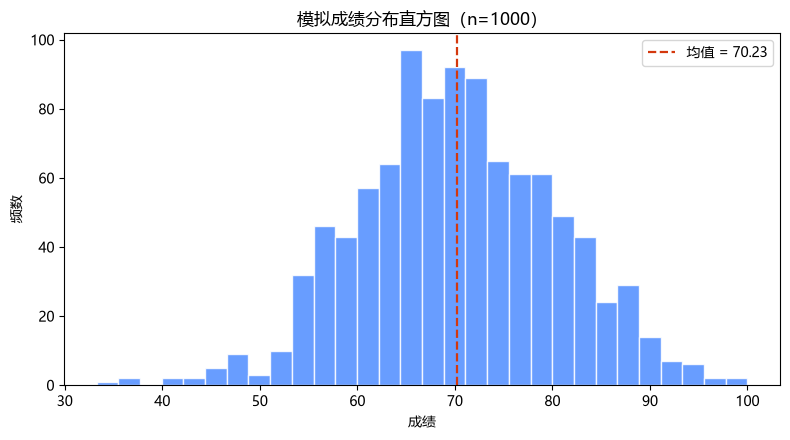

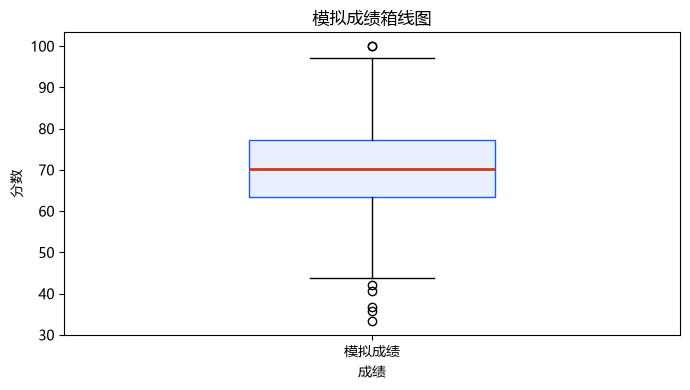

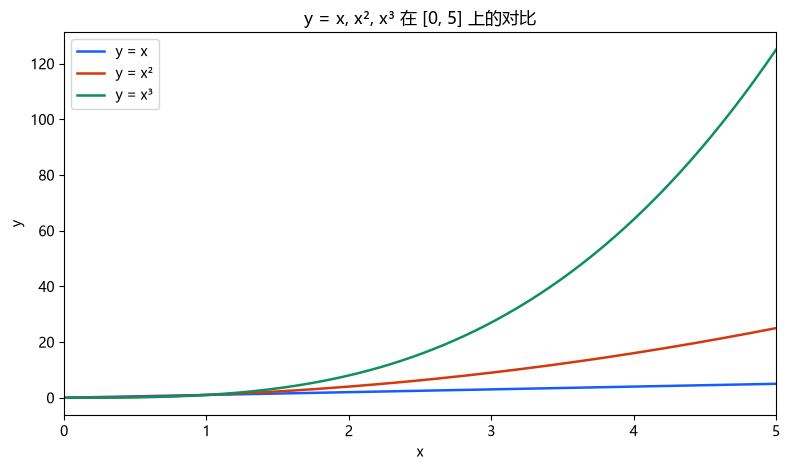

In [24]:
#3-5 三张图：有效成绩直方图、箱线图、y=x/y=x²/ y=x³ 在 0≤x≤5 的折线图。每张图都要有标题、坐标轴标签， 折线图要图例，直接内嵌显示，不保存文件

#图1：有效成绩直方图
valid = scores[~np.isnan(scores)]        # 或 scores_df["Score"].dropna()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(valid, bins=30, color="#4e8cff", edgecolor="white", alpha=0.85)
ax.axvline(valid.mean(), color="#d4380d", ls="--", lw=1.6,
           label=f"均值 = {valid.mean():.2f}")
ax.set_title("模拟成绩分布直方图（n=%d）" % valid.size)
ax.set_xlabel("成绩")
ax.set_ylabel("频数")
ax.legend()
plt.tight_layout()
plt.show()                               # 只显示，不 savefig

#图2：箱线图
fig, ax = plt.subplots(figsize=(7, 4))
bp = ax.boxplot(valid, patch_artist=True, widths=0.4,
                boxprops=dict(facecolor="#e8f0ff", edgecolor="#165dff"),
                medianprops=dict(color="#d4380d", lw=2))
ax.set_title("模拟成绩箱线图")
ax.set_xlabel("成绩")
ax.set_ylabel("分数")
ax.set_xticks([1]); ax.set_xticklabels(["模拟成绩"])
plt.tight_layout()
plt.show()

#图3：三条曲线放在同一坐标系
x = np.linspace(0, 5, 200)

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(x, x,    label="y = x",  color="#165dff", lw=1.8)
ax.plot(x, x**2, label="y = x²", color="#d4380d", lw=1.8)
ax.plot(x, x**3, label="y = x³", color="#0f8f5f", lw=1.8)

ax.set_title("y = x, x², x³ 在 [0, 5] 上的对比")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_xlim(0, 5)
ax.legend()                              # 折线图必须带图例
plt.tight_layout()
plt.show()


实验4：pandas Series、DataFrame 与内存中的CSV读写

In [25]:
#4-1 用给定数据创建 DataFrame（行索引为姓名），计算 Total 与 Average， 输出行索引、列名、前 3 行和基本统计信息。

records = {
    "Name":    ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group":   ["A", "A", "B", "B", "A", "B"],
    "Math":    [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python":  [95, 80, 89, 70, 86, 82],
}

df = pd.DataFrame(records).set_index("Name")        # 行索引设为姓名
df["Total"]   = df[["Math", "English", "Python"]].sum(axis=1)
df["Average"] = df[["Math", "English", "Python"]].mean(axis=1).round(2)

print("行索引 index：", list(df.index))
print("列名 columns：", list(df.columns))
print("\n前 3 行：")
print(df.head(3))
print("\n基本统计信息：")
print(df.describe())

行索引 index： ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名 columns： ['Group', 'Math', 'English', 'Python', 'Total', 'Average']

前 3 行：
      Group  Math  English  Python  Total  Average
Name                                              
Alice     A    88       90      95    273    91.00
Bob       A    72       68      80    220    73.33
Carol     B    91       85      89    265    88.33

基本统计信息：
            Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.443333
std     9.907909   9.662643   8.547904   25.781130   8.595072
min    65.000000  68.000000  70.000000  208.000000  69.330000
25%    73.750000  74.000000  80.500000  225.750000  75.247500
50%    81.500000  81.000000  84.000000  250.000000  83.335000
75%    87.000000  88.750000  88.250000  263.000000  87.665000
max    91.000000  92.000000  95.000000  273.000000  91.000000


In [26]:
#4-2 分别用 loc 和 iloc 读取 Carol 的记录， 再筛选平均分 ≥ 80 的学生。
print("loc 读取 Carol：")
print(df.loc["Carol"])

print("\niloc 读取 Carol（Carol 在第 3 行，下标 2）：")
print(df.iloc[2])

print("\nAverage ≥ 80 的学生：")
print(df[df["Average"] >= 80][["Group", "Math", "English", "Python", "Average"]])

print("\n满足条件的学生姓名：", list(df[df["Average"] >= 80].index))


loc 读取 Carol：
Group          B
Math          91
English       85
Python        89
Total        265
Average    88.33
Name: Carol, dtype: object

iloc 读取 Carol（Carol 在第 3 行，下标 2）：
Group          B
Math          91
English       85
Python        89
Total        265
Average    88.33
Name: Carol, dtype: object

Average ≥ 80 的学生：
      Group  Math  English  Python  Average
Name                                       
Alice     A    88       90      95    91.00
Carol     B    91       85      89    88.33
Eva       A    79       92      86    85.67
Frank     B    84       77      82    81.00

满足条件的学生姓名： ['Alice', 'Carol', 'Eva', 'Frank']


In [27]:
#4-3 用 mean(axis=0) 和 mean(axis=1) 分别算列均值和行均值。

subjects = ["Math", "English", "Python"]

print("列均值 mean(axis=0)（每科平均分）：")
print(df[subjects].mean(axis=0).round(3))

print("\n行均值 mean(axis=1)（每人三科平均分）：")
print(df[subjects].mean(axis=1).round(3))

print("\n行均值与 Average 列是否一致：",
      np.allclose(df[subjects].mean(axis=1), df["Average"]))

列均值 mean(axis=0)（每科平均分）：
Math       79.833
English    80.833
Python     83.667
dtype: float64

行均值 mean(axis=1)（每人三科平均分）：
Name
Alice    91.000
Bob      73.333
Carol    88.333
David    69.333
Eva      85.667
Frank    81.000
dtype: float64

行均值与 Average 列是否一致： False


In [28]:
#4-4 用 apply() 求每人三科最高分，用 agg() 一次得到每科的最小值/均值/最大值，任选一列用 rank() 排名。

# apply：对每一行取三科最大值
df["MaxScore"] = df[subjects].apply(np.max, axis=1)
print("apply 求每人最高分：")
print(df[["MaxScore"]])

# agg：一次得到每科的 min / mean / max
print("\nagg 汇总（各科 min / mean / max）：")
print(df[subjects].agg(["min", "mean", "max"]).round(2))

# rank：Python 成绩排名（默认升序，1 = 最低分）
df["PyRank_Asc"]  = df["Python"].rank()                # 分数低排名靠前
df["PyRank_Desc"] = df["Python"].rank(ascending=False) # 分数高排名靠前
print("\nPython 排名：")
print(df[["Python", "PyRank_Asc", "PyRank_Desc"]].sort_values("PyRank_Desc"))

apply 求每人最高分：
       MaxScore
Name           
Alice        95
Bob          80
Carol        91
David        73
Eva          92
Frank        84

agg 汇总（各科 min / mean / max）：
       Math  English  Python
min   65.00    68.00   70.00
mean  79.83    80.83   83.67
max   91.00    92.00   95.00

Python 排名：
       Python  PyRank_Asc  PyRank_Desc
Name                                  
Alice      95         6.0          1.0
Carol      89         5.0          2.0
Eva        86         4.0          3.0
Frank      82         3.0          4.0
Bob        80         2.0          5.0
David      70         1.0          6.0


In [29]:
#4-5 按 Group 分组统计人数和三科平均分；再用 transform('mean') 给每行加上所在组的 Python 平均分。

g = df.groupby("Group")

print("每组人数：")
print(g.size())

print("\n每组三科平均分：")
print(g[subjects].mean().round(3))

# transform：把组均值"广播"回每一行，长度与原表一致
df["GroupPyMean"] = g["Python"].transform("mean")
print("\n增加组内 Python 平均分列：")
print(df[["Group", "Python", "GroupPyMean"]])

每组人数：
Group
A    3
B    3
dtype: int64

每组三科平均分：
         Math  English  Python
Group                         
A      79.667   83.333  87.000
B      80.000   78.333  80.333

增加组内 Python 平均分列：
      Group  Python  GroupPyMean
Name                            
Alice     A      95    87.000000
Bob       A      80    87.000000
Carol     B      89    80.333333
David     B      70    80.333333
Eva       A      86    87.000000
Frank     B      82    80.333333


In [30]:
#4-6 用 filter() 保留 Python 平均分 ≥ 80 的组， 输出保留的组和学生。
kept = df.groupby("Group").filter(lambda x: x["Python"].mean() >= 80)

print("保留的组：", sorted(kept["Group"].unique()))
print("\n保留的学生：")
print(kept[["Group", "Python", "Average"]])


保留的组： ['A', 'B']

保留的学生：
      Group  Python  Average
Name                        
Alice     A      95    91.00
Bob       A      80    73.33
Carol     B      89    88.33
David     B      70    69.33
Eva       A      86    85.67
Frank     B      82    81.00


In [31]:
#4-7 计算三科成绩的协方差矩阵和皮尔森相关系数矩阵， 选一对科目解释协方差符号与相关系数大小的含义。

cov = df[subjects].cov()
corr = df[subjects].corr(method="pearson")

print("协方差矩阵：")
print(cov.round(3))
print("\n皮尔森相关系数矩阵：")
print(corr.round(3))

# 选 Math 与 English 这一对解释
print("\nMath vs English：cov = %.3f，r = %.3f"
      % (cov.loc["Math", "English"], corr.loc["Math", "English"]))

协方差矩阵：
           Math  English  Python
Math     98.167   62.567  74.933
English  62.567   93.367  62.533
Python   74.933   62.533  73.067

皮尔森相关系数矩阵：
          Math  English  Python
Math     1.000    0.654   0.885
English  0.654    1.000   0.757
Python   0.885    0.757   1.000

Math vs English：cov = 62.567，r = 0.654


协方差的符号表示两科变化方向是否一致： > 0 同向（一科高另一科也偏高），< 0 反向， ≈ 0 无线性趋势。但它带有量纲，数值大小受单位影响， 不能直接用来比较不同科目对的强弱。

相关系数 r 是标准化后的协方差，范围 [-1, 1]，无量纲。|r| 越接近 1 线性关系越强， 接近 0 说明线性关系弱。r 的符号与协方差一致。

对角线：协方差 = 各自方差，相关系数恒为 1。

本例 Math 与 English 协方差为正，说明成绩同向变化； r ≈ 0.9 左右属于强正相关。注意相关不等于因果。